# Trade Cost and Utility

This example demonstrates how to trade the life-cycle cost of designs against what they achieve with the `tatc.tradespace` module: costs estimated from a cost model and each design's deployment, with uncertain growth whose quantiles give the cost at a confidence level, a budget as a requirement, the probability that one design costs more than another when designs share the cost risk of their components, and utilities that weigh several objectives by a stakeholder's preferences.

It continues the example `SearchTradeSpace`, whose design space and study it imports from `trade_space_example.py` (beside the notebooks). The evaluations of every design are taken from the study's store if `SearchTradeSpace` was run before (or are evaluated again, in a few minutes). Its replicates are refined where the efficiency of designs is uncertain, as in `RankUncertainDesigns` (from the store, if that example was run before).

In [1]:
from trade_space_example import OBJECTIVES, describe, designs, planes_name, study
from tatc.tradespace import Criteria, refine

# the evaluations of every design, with replicates added where their efficiency is uncertain (see RankUncertainDesigns)
results = study.run(designs)
TOLERANCE = {"sufficient": 1.0}  # percentage points of the share that do not matter
CRITERIA = Criteria(OBJECTIVES, tolerance=TOLERANCE)
refinement = refine(study, CRITERIA, results, step=5, max_replicates=40, precision=0.5, n_resamples=1000)
print(f"{len(refinement.results)} evaluations")

5695 evaluations


## Trade Cost Against Sufficiency

The numbers of satellites and planes are proxies of cost. A `CostModel` estimates the life-cycle cost of each design from the costs of its satellites (the development of each type, and the production of its units on a learning curve), launches (here, a small launcher for every three satellites of a plane), and operations, given by the study (TAT-C does not include cost-estimating relationships). The costs here are illustrative, in millions of dollars. The evaluation adds the cost and its elements to each record (and the years by which the design is `deployed`), for the satellites of each design's imager (`kind`): a wider field of regard costs more to develop and build. The deployment of each design (`DeploymentSchedule.plan`) dates the costs, from rates, so that each design's schedule follows from its satellites and planes: development over three years, then the production of the satellites on one line at four a year, plane by plane, each plane launched when its satellites are ready (in launches of up to three satellites, at most one every half year), and operations from each launch to the end of the mission (five years after the first launch). The dated costs give the present value of the cost (`cost present`, discounted at 3% a year) and the cost of the most expensive year (`cost peak annual`), for annual budgets.

The growth of the cost of development is uncertain (an `Uncertain` parameter, from 0.9 to 1.6 times the estimate, most likely 1), drawn for each replicate, so that statistics over the replicates give the cost at a confidence level: here, the 0.7 quantile (`cost p70`), as budgets are often set. A requirement keeps the designs whose cost at 70% confidence is within a budget, and the front trades this cost against the share of points sufficiently sampled. (Cost depends only on the design, so a constraint of the design space could exclude designs over a budget before they are evaluated, with the cost without growth.)

In [2]:
from tatc.tradespace import Quantile, Requirement, aggregate, pareto_probability

BUDGET = 150  # millions of dollars, at 70% confidence
COST = Criteria(
    {"cost p70": "min", "sufficient": "max"},
    statistics={"cost p70": Quantile("cost", 0.7)},
    requirements=[Requirement("cost p70", "<=", BUDGET)],
    tolerance=TOLERANCE,
)
ELEMENTS = ["cost development", "cost production", "cost launch", "cost operations"]
DATED = ["cost present", "cost peak annual"]

# the probability that each design is efficient, with its values (such as its satellites and planes, and the years by
# which it is deployed), and the means of the elements of its cost
costed = pareto_probability(refinement.results, COST, n_resamples=1000)
means = aggregate(refinement.results, [*ELEMENTS, *DATED], design_columns=[]).set_index("design")
costed[[*ELEMENTS, *DATED]] = means.loc[costed.design, [*ELEMENTS, *DATED]].to_numpy()
costed["description"] = costed.apply(describe, axis=1)
efficient = costed[costed.pareto_probability >= 0.5]
print(
    f"{costed.meets_requirements.sum()} of {len(costed)} designs cost at most {BUDGET} at 70% confidence, "
    + f"of which {len(efficient)} are efficient in at least half of the resamples"
)
# the most sufficient of these at each cost
efficient.sort_values(["cost p70", "sufficient"], ascending=[True, False]).drop_duplicates("cost p70")[
    ["description", "satellites", "planes", "deployed", "cost p70", *ELEMENTS, *DATED, "sufficient", "pareto_probability"]
].round(1)

520 of 1096 designs cost at most 150 at 70% confidence, of which 46 are efficient in at least half of the resamples


,description,satellites,planes,deployed,cost p70,cost development,cost production,cost launch,cost operations,cost present,cost peak annual,sufficient,pareto_probability
635,"700 km, 30 deg FOR, SSO: 1 at 06:00",1,1,3.2,83.6,44.4,12.0,8.0,17.5,75.5,23.5,1.0,1.0
910,"800 km, 30 deg FOR, SSO: 2 at 06:00",2,1,3.5,96.9,44.4,22.8,8.0,20.0,87.2,30.8,2.6,0.9
826,"800 km, 30 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,104.7,44.4,22.8,16.0,19.8,94.3,42.3,6.2,0.9
824,"800 km, 30 deg FOR, Walker 45 deg: 1 x 3 (spac...",3,1,3.8,109.6,44.4,33.0,8.0,22.5,98.2,41.0,7.8,1.0
835,"800 km, 30 deg FOR, Walker 45 deg: 3 x 1 (spac...",3,3,4.2,124.8,44.4,33.0,24.0,21.8,112.2,52.5,11.2,1.0
828,"800 km, 30 deg FOR, Walker 45 deg: 2 x 2 (spac...",4,2,4.0,129.3,44.4,42.7,16.0,24.5,115.9,50.7,22.2,1.0
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,139.2,66.7,34.2,16.0,19.8,126.0,53.7,30.2,1.0
845,"800 km, 30 deg FOR, Walker 45 deg: 4 x 1 (spac...",4,4,4.8,144.3,44.4,42.7,32.0,23.5,129.2,62.2,31.0,0.7
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3,1,3.8,149.1,66.7,49.4,8.0,22.5,134.4,57.4,38.0,0.6


520 of the 1,096 designs cost at most 150 million dollars at 70% confidence. Along the front, money buys sufficiency in steps: one satellite (84 million at 70% confidence, of which 44 million on average develops it) samples 1% of the points sufficiently; a second satellite in its plane, 3%, and in a second plane, 6%; four satellites in two Walker planes (129 million), 22%. The planes now have a price: four satellites in four planes sample more points sufficiently than in two (31% against 22%, as more planes spread the samples in time), at twice the cost of launches (32 million against 16). The wider field of regard joins the front only near the budget, where its development (67 million against 44) is worth its swath: two satellites with the wider imager sample 30% of the points for 139 million, about as many as four with the narrower one in four planes, and three of them 38% for 149 million, the most within the budget. The designs that sample nearly every point (six to nine satellites) cost more than the budget.

Each design's schedule follows from its satellites and planes (`deployed`, years from the start of development to the launch of its last plane): one satellite is launched 3.2 years after development starts; four satellites in two planes take a year to produce, and are deployed after 4.0 years; and four satellites in four planes, after 4.8 years, as each plane takes a launch and launches are half a year apart. Dated, the costs are worth 8 to 9% less at present (at 3% a year), as most are incurred three or more years from now. The most expensive year is the one after development, in which the satellites are produced and the first are launched: four satellites in four planes need 62 million in that year, and one satellite 24 million. A budget of annual funding would limit the satellites produced in a year, which a slower production rate would spread over more years, at the cost of deploying later.

The growth of the cost of development affects every design alike in a replicate (common random numbers), so it shifts the costs at 70% confidence more for designs whose development costs more, here those of the wider imager. With five replicates of most designs, the 0.7 quantile of their costs is a coarse estimate: an evaluation that costs little more than the cost model (unlike the analysis of sampling) could draw more replicates of the cost alone.

## Compare Uncertain Costs

The growth of cost above is one factor of the development of every design, drawn alike in each replicate (common random numbers): designs share all of their cost risk. Cost risk has more structure (M. W. Maier, K. L. Yeakel, and E. B. Wendoloski, "Cost Variance Analysis in Constellation Architecture Studies," *IEEE Systems Journal* 17(2), 2023). The cost of a type of satellite is the sum of those of its components (`Component`, here its bus and imager), each growing by its maturity (a `Triangular` distribution, from formal risk assessments: wider and skewed further up for new components than for existing ones), and the growths of the components are correlated (here by 0.5, `CostModel.correlation`), as costs estimated alike tend to be underestimated together. The growth of each component is drawn from scores, standard normal values of each component and a common score (uncertain parameters of the design space, from `risk_space`), which common random numbers give alike to every design of a replicate (`CostModel.draw`): designs of the same imager share all of its cost risk, and designs of different imagers share the growth of the bus and the common score. Here, the bus exists, the narrower imager modifies an existing one, and the wider imager is new; their expected costs are about those of the cost model above.

A study of the costs alone (whose evaluation estimates the cost of each design's deployment, with the growth of its components drawn from its scores) evaluates the most sufficient efficient design at each cost (as in the table above) in 500 replicates, with common random numbers and without. Its results give the probability that each design costs more than each other (`exceedance`), plotted with `plot_exceedance` in order of the mean cost:

30 deg: expected development 40.1, first unit 12.1
60 deg: expected development 59.1, first unit 18.2


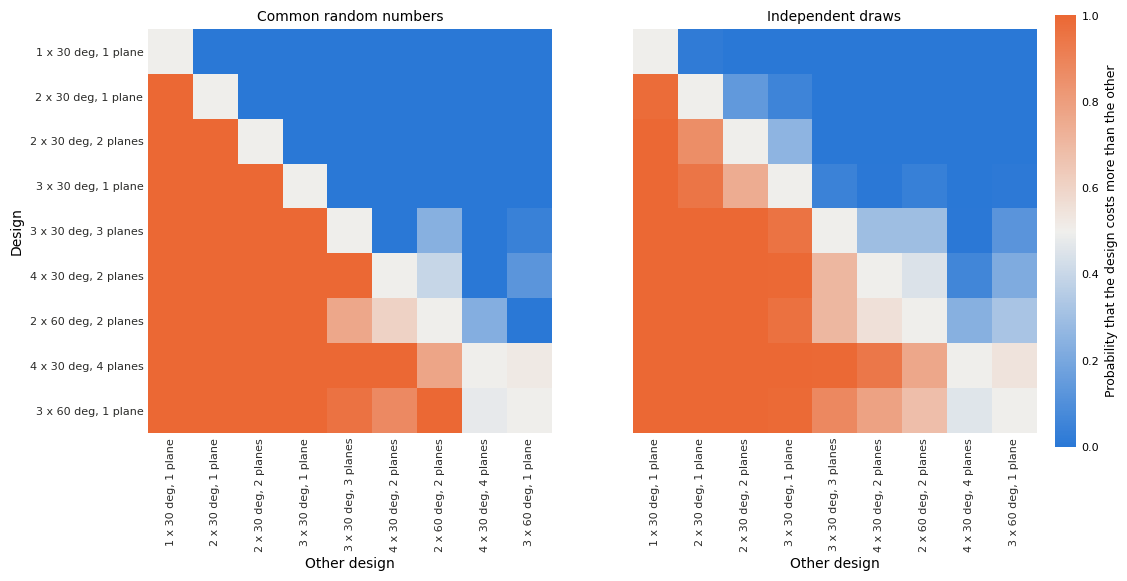

In [3]:
import dataclasses

import matplotlib.pyplot as plt
import pandas as pd

from trade_space_example import COST_MODEL, SCHEDULE, space
from tatc.tradespace import Component, SatelliteCost, Study, Triangular, exceedance, plot_exceedance, risk_space

# the growth of the costs of a component by its maturity: lowest, most likely (the estimate), and highest (Maier et
# al., 2023, Table I)
MATURITY = {
    "new": Triangular(0.827, 2.274),
    "major modification": Triangular(0.864, 1.993),
    "modified": Triangular(0.904, 1.708),
    "minor modification": Triangular(0.943, 1.423),
    "existing": Triangular(0.981, 1.140),
}
# illustrative costs (millions of dollars) of the components of the satellites of each imager: an existing bus, a
# modified imager of 30 degrees, and a new imager of 60 degrees, whose growths are correlated by 0.5
BUS = Component("bus", development=20, first_unit=7, growth=MATURITY["existing"])
COMPONENT_COSTS = dataclasses.replace(
    COST_MODEL,
    satellites={
        30: SatelliteCost(
            components=[BUS, Component("imager 30", development=16, first_unit=4, growth=MATURITY["modified"])],
            learning_rate=0.9,
            mass=60,
        ),
        60: SatelliteCost(
            components=[BUS, Component("imager 60", development=28, first_unit=8, growth=MATURITY["new"])],
            learning_rate=0.9,
            mass=90,
        ),
    },
    correlation=0.5,
)
for kind, satellite in COMPONENT_COSTS.satellites.items():
    print(
        f"{kind} deg: expected development {satellite.total_development:.1f}, first unit {satellite.total_first_unit:.1f}"
    )
# the scores of the components and the common score, drawn for each replicate
costed_space = space.extend(cost_risk=risk_space(COMPONENT_COSTS))


def deploy(d):
    """The deployment of a design's satellites."""
    return SCHEDULE.plan(d.layout, kind=d.field_of_regard)


def estimate(deployment, design):
    """The cost of a deployment, with the growth of the components drawn from the design's scores."""
    return COMPONENT_COSTS.draw(design.cost_risk).estimate(deployment).metrics()


# the most sufficient efficient design at each cost (as designs of the space with scores), evaluated with common
# random numbers and without
compared = efficient.sort_values(["cost p70", "sufficient"], ascending=[True, False]).drop_duplicates("cost p70")
compared_designs = [costed_space.design(d) for d in space.designs_of(compared)]
labels = {
    d.key: f"{row.satellites:.0f} x {d.field_of_regard} deg, {planes_name(row.planes)}"
    for d, row in zip(compared_designs, compared.itertuples())
}
costs = Study(costed_space, deploy, estimate, replicates=500)
shared_results = costs.run(compared_designs)
independent_results = costs.replace(common_random_numbers=False).run(compared_designs)
shared = exceedance(shared_results, "cost")  # in order of the mean cost
order = list(dict.fromkeys(shared.design))
independent = exceedance(independent_results, "cost", order)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, frame, title in zip(axes, [shared, independent], ["Common random numbers", "Independent draws"]):
    plot_exceedance(frame, labels=labels, colorbar=False, ax=ax)
    ax.set_title(title, fontsize=10)
axes[1].set(ylabel="")
axes[1].tick_params(labelleft=False)
scale = fig.colorbar(axes[0].images[0], ax=axes, fraction=0.025, pad=0.02)
scale.set_label("Probability that the design costs more than the other", fontsize=9)
scale.ax.tick_params(labelsize=8, length=0)
scale.outline.set_visible(False)
plt.show()

With common random numbers (left), the designs of the narrower imager are ordered in every replicate: they share the growth of all of their components, so that the design with more satellites or planes costs more whatever the growth, although neighbors differ by less than their costs spread (three satellites in one plane cost 5 million dollars more than two in two planes, and each spreads by about 5 million). So are the two designs of the wider imager, 10 million apart while each spreads by 15 to 17 million. Designs of different imagers share the growth of the bus, which spreads little, and the common score, but the spread of the costs of the wider imager is mostly the new imager's own, and their order is open where their costs are near (the pale cells between the designs of each imager): two satellites of the wider imager in two planes cost more than four of the narrower one in two planes in 60% of the replicates, as the growth of the new imager is skewed far up. With independent draws (right), the order of designs of the same imager is open as well: their costs spread as much as before, but no longer together.

In [4]:
# the pairs whose order the replicates settle (one design costs more in at least 95% of them), of the same imager
# and of different imagers
position = {key: k for k, key in enumerate(order)}
imager = {d.key: d.field_of_regard for d in compared_designs}
for name, frame in [("common random numbers", shared), ("independent draws", independent)]:
    pairs = frame[frame.design.map(position) > frame.other.map(position)]
    settled = (pairs.exceedance >= 0.95) | (pairs.exceedance <= 0.05)
    same = pairs.design.map(imager) == pairs.other.map(imager)
    print(
        f"{name}: {settled[same].sum()} of {same.sum()} pairs of the same imager settled, "
        + f"{settled[~same].sum()} of {(~same).sum()} of different imagers"
    )

# each design against the one before it in order of cost: the mean and standard deviation of its cost, the mean
# difference, and the probability that it costs more, with common random numbers and with independent draws
spread = shared_results.groupby("design")["cost"].agg(["mean", "std"])
neighbors = pd.DataFrame({"design": order[1:], "other": order[:-1]})
neighbors = neighbors.merge(shared, on=["design", "other"]).merge(
    independent[["design", "other", "exceedance"]], on=["design", "other"], suffixes=(" (common)", " (independent)")
)
neighbors["cost"] = spread.loc[neighbors.design, "mean"].to_numpy()
neighbors["cost std"] = spread.loc[neighbors.design, "std"].to_numpy()
neighbors["design"] = neighbors.design.map(labels)
neighbors["other"] = neighbors.other.map(labels)
neighbors[
    ["design", "other", "cost", "cost std", "cost difference", "exceedance (common)", "exceedance (independent)"]
].round(2)

common random numbers: 22 of 22 pairs of the same imager settled, 9 of 14 of different imagers
independent draws: 16 of 22 pairs of the same imager settled, 8 of 14 of different imagers


,design,other,cost,cost std,cost difference,exceedance (common),exceedance (independent)
0,"2 x 30 deg, 1 plane","1 x 30 deg, 1 plane",91.21,4.79,13.41,1.00,0.98
1,"2 x 30 deg, 2 planes","2 x 30 deg, 1 plane",98.96,4.79,7.75,1.00,0.86
2,"3 x 30 deg, 1 plane","2 x 30 deg, 2 planes",103.98,5.51,5.01,1.00,0.75
3,"3 x 30 deg, 3 planes","3 x 30 deg, 1 plane",119.23,5.51,15.25,1.00,0.95
4,"4 x 30 deg, 2 planes","3 x 30 deg, 3 planes",123.80,6.19,4.57,1.00,0.70
5,"2 x 60 deg, 2 planes","4 x 30 deg, 2 planes",129.60,14.69,5.80,0.60,0.55
6,"4 x 30 deg, 4 planes","2 x 60 deg, 2 planes",138.80,6.19,9.20,0.77,0.76
7,"3 x 60 deg, 1 plane","4 x 30 deg, 4 planes",139.79,17.01,0.99,0.48,0.46


Along the order of cost, each design of the narrower imager costs more than the one before it in every replicate with common random numbers, and in 70 to 98% of them with independent draws: neighbors 5 million dollars apart (three satellites in one plane after two in two planes, and four in two planes after three in three planes) change order in a quarter to a third of the replicates drawn independently, as each spreads by 5 to 6 million. Of the pairs of designs of the same imager, all 22 are settled (one costs more in at least 95% of the replicates) with common random numbers and 16 with independent draws; of the pairs of different imagers, 9 of 14 with common random numbers and 8 with independent draws, as what they share (the bus, and the common score) spreads less than the new imager. Costs that share their risk settle the order of designs that differ by less than their costs spread, as far as they share what spreads, which comparisons of their quantiles, or of costs drawn independently, cannot see. Here, the order of the front's designs by cost is open only where they change imager, where a choice within a budget rests on the growth of the new imager.

The growth of each type of satellite is the simplest structure of this kind (a factor of each kind, such as `growth={"development": {30: "growth_30", 60: "growth_60"}}` in a `MissionPlan`), and a `MissionPlan` draws the growth of components from the scores of each design (`scores="cost_risk"`) in an `ObservationStudy`. The scores are uncertain parameters of the design space, so that the variance of costs, or of their differences, may be attributed to each component (`attribute_variance`, with the paths of the scores, such as `cost_risk.imager 60`) and to the risk that components share (`cost_risk.common`), and a scenario may fix a score (such as at a high quantile of the growth of the new imager).

## Trade Utility Against Cost

Sufficiency and accuracy are objectives of `SearchTradeSpace`, each in its own units. A stakeholder who values both weighs them, and a utility makes the weights explicit (`Utility`): a single-attribute utility of each metric, from 0 at its worst acceptable value to 1 at its best (here, linear in the share of points sampled sufficiently, `LinearUtility`, and concave in the share sampled accurately, `ExponentialUtility`, as the first points accurately sampled matter most), combined by weights. Two stakeholders weigh the shares differently: one mostly sufficiency (0.7 against 0.3), as a center that counts samples for forecasts might, and the other mostly accuracy (0.3 against 0.7), as one that estimates daily means might. Each design's utility is that of its means: the shares vary between replicates mostly as noise of the sample of points, which the expected utility (the mean of the utility of each replicate, `Mean(utility)`) would penalize as if it were a risk. The figure plots each stakeholder's utility of every design against its cost at 70% confidence (as above), with the front of each ringed:

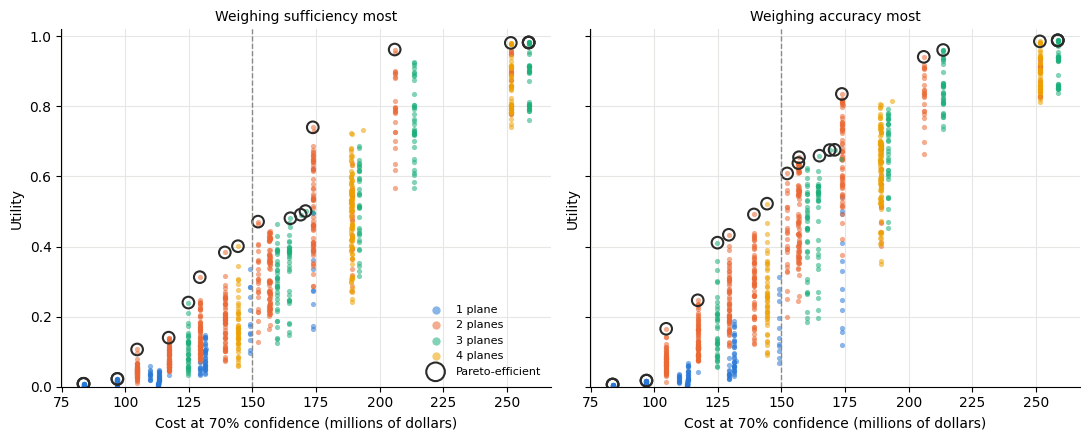

In [5]:
import matplotlib.pyplot as plt

from tatc.tradespace import ExponentialUtility, LinearUtility, Utility, pareto_front, plot_designs, style_axes
from tatc.tradespace.plotting import GRAY

# the utility of the shares sampled sufficiently (linear) and accurately (concave: the first points matter most), for
# two stakeholders who weigh them differently
CURVES = {"sufficient": LinearUtility(0, 100), "accurate": ExponentialUtility(0, 100, risk=2)}
STAKEHOLDERS = {
    "sufficiency": Utility(CURVES, weights={"sufficient": 0.7, "accurate": 0.3}),
    "accuracy": Utility(CURVES, weights={"sufficient": 0.3, "accurate": 0.7}),
}
means = aggregate(
    refinement.results,
    statistics={"sufficient": "sufficient", "accurate": "accurate", "cost p70": Quantile("cost", 0.7)},
).set_index("design")
means["description"] = means.apply(describe, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
judged = {}
for ax, (name, utility) in zip(axes, STAKEHOLDERS.items()):
    judged[name] = means.assign(utility=utility(means))
    judged[name]["pareto"] = pareto_front(judged[name], {"utility": "max", "cost p70": "min"})
    legend = "lower right" if ax is axes[0] else None
    plot_designs(judged[name], "cost p70", "utility", by="planes", front="pareto", names=planes_name, legend=legend, ax=ax)
    ax.axvline(BUDGET, color=GRAY, lw=1, ls="--")
    ax.set(xlabel="Cost at 70% confidence (millions of dollars)", ylabel="Utility", ylim=(0, 1.02))
    ax.set_title(f"Weighing {name} most", fontsize=10)
    style_axes(ax, grid="both")
fig.tight_layout()
plt.show()

The stakeholders' fronts share most of their designs. Those efficient for one stakeholder and not the other:

In [6]:
# the designs efficient for one stakeholder and not the other
compared = means[["description", "satellites", "planes", "sufficient", "accurate", "cost p70"]].copy()
for name in STAKEHOLDERS:
    compared[f"utility ({name})"] = judged[name]["utility"]
    compared[f"efficient ({name})"] = judged[name]["pareto"]
print(f"{(compared['efficient (sufficiency)'] & compared['efficient (accuracy)']).sum()} designs are efficient for both")
compared[compared["efficient (sufficiency)"] != compared["efficient (accuracy)"]].sort_values("cost p70").round(2)

20 designs are efficient for both


,description,satellites,planes,sufficient,accurate,cost p70,utility (sufficiency),efficient (sufficiency),utility (accuracy),efficient (accuracy)
design,,,,,,,,,,
828c0027d01f,"800 km, 60 deg FOR, SSO: 1 at 12:00, 2 at 18:00",3,2,29.2,57.0,156.65,0.44,False,0.64,True
c576e2e2dbd1,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3,2,28.8,60.6,156.90,0.45,False,0.66,True
6ba50f2632cd,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4,2,69.6,65.4,173.73,0.74,True,0.80,False
3690f1194419,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4,2,57.6,85.4,173.73,0.69,False,0.84,True
64cf6542c326,"800 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6,3,90.2,95.8,213.53,0.93,False,0.96,True


Within the budget, the stakeholders agree: every design efficient for either of them up to 150 million dollars is efficient for both, as more satellites in more planes buy both shares. Beyond the budget, they part. For 174 million dollars at 70% confidence, the stakeholder of sufficiency prefers four satellites in two Walker planes (70% of the points sufficiently sampled and 65% accurately), and the stakeholder of accuracy four in two sun-synchronous planes crossing at 09:00 and 15:00 (58% and 85%), whose planes spread the samples over the day. The stakeholder of accuracy also finds three satellites in two sun-synchronous planes efficient for 157 million (57 to 61% accurately sampled), and six in three Walker planes for 214 million (96%), which the stakeholder of sufficiency passes over. A utility is a metric of any statistic (such as `Quantile(utility, 0.1)`, the utility that a design exceeds in 90% of the replicates, for risks that the replicates draw) and so an objective of the searches as well; a multiplicative utility (`form="multiplicative"`) makes the shares complements, both of which a design must serve, or substitutes, either of which suffices.

## Summary

* A `CostModel` estimates the life-cycle cost of each deployment from the costs of its satellites, launches, and operations (given by the study, as TAT-C includes no cost-estimating relationships), dated by the deployment that a `DeploymentSchedule` plans from rates of production and launch, with uncertain growth whose quantiles give the cost at a confidence level, as an objective or a requirement in place of the numbers of satellites and planes.
* The costs of the components of satellites (`Component`), whose growth by their maturity is drawn from scores that are uncertain parameters of the design space (`risk_space`, `CostModel.draw`), share cost risk between the designs that share components: with common random numbers, the order of designs of the same imager is settled although they differ by less than their costs spread, and the probability that each design costs more than each other (`exceedance`, `plot_exceedance`) shows where the order of the front is open.
* A `Utility` weighs metrics by a stakeholder's preferences (a single-attribute utility of each, combined by weights) into one objective against cost, and is a metric of any statistic (its mean is the expected utility): here, stakeholders who weigh sufficiency or accuracy most agree within the budget and part beyond it.